# Rope Bridge with Fixed Planks — Timefold vs Graph vs MIP

*© 2026 Taras Bulubas — all rights reserved. You may open, run and modify this
notebook in Google Colab for personal, non-commercial exploration; any other
use requires prior written permission. See `LICENSE`.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tbulubas/rope-bridge-solver-comparison/blob/main/notebooks/solver_comparison.ipynb)

One small planning problem, solved in three ways: with **Timefold** (local
search), with **graph algorithms** and as a **MIP** (SCIP and CP-SAT). This
notebook

1. states the problem and solves one bridge;
2. runs the graph algorithms and the MIP models live and, where Java is
   available, the Timefold models too;
3. reads the benchmark results in `docs/benchmark/` and shows how the
   approaches scale;
4. adds a new requirement — pallets are cut from stock pieces — and shows
   which approach can take it.

The problem is described in [`docs/problem-statement.md`](../docs/problem-statement.md),
the models in [`docs/mip-model.md`](../docs/mip-model.md) and
[`docs/timefold-models.md`](../docs/timefold-models.md).

**Where it runs**

- **Google Colab** — open it with the badge above and choose *Runtime → Run all*.
  The first code cell fetches the repository from GitHub and installs the
  `fixed_planks` package. Your changes stay in your own copy; save it with
  *File → Save a copy in Drive* to keep them.
- **Locally** — `make notebook` opens it in JupyterLab in the project's `.venv`.

The Timefold models are written in Kotlin and run on the JVM. The notebook is
Python, so it shows their stored benchmark results; the one live Timefold cell
runs only where Java 21 or newer and the built runner (`make timefold`) are
present, and is skipped otherwise.

In [1]:
import importlib
import importlib.util
import subprocess
import sys
from pathlib import Path

REPOSITORY = "https://github.com/tbulubas/rope-bridge-solver-comparison.git"

here = Path.cwd()
ROOT = here.parent if here.name == "notebooks" else here
if not (ROOT / "docs" / "benchmark").is_dir():  # e.g. Google Colab: fetch the repository once
    ROOT = here / "rope-bridge-solver-comparison"
    if not ROOT.is_dir():
        print("Cloning the repository from GitHub …")
        subprocess.check_call(["git", "clone", "--quiet", "--depth", "1", REPOSITORY, str(ROOT)])
if importlib.util.find_spec("fixed_planks") is None:
    print("Installing the fixed_planks package …")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", f"{ROOT}[plot]"])
    importlib.invalidate_caches()
print("ready")

ready


In [2]:
import json
import shutil
import tempfile
import time

import matplotlib.pyplot as plt
import pandas as pd

from fixed_planks import random_instance, verify, verify_cutting
from fixed_planks.cli import run_solver
from fixed_planks.draw import INK, MUTED, SERIES, draw_cutting, draw_plan, style
from fixed_planks.solution import BridgePlan

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": "#fcfcfb"})

# Every solver keeps its colour in every chart.
SOLVERS = ["graph", "graph-sequential", "scip-flow", "cpsat-flow", "scip-cover", "cpsat-cover",
           "timefold-joints", "timefold-pallets"]
COLOUR = dict(zip(SOLVERS, SERIES))

## 1. The problem and one bridge

A rope bridge has its **planks** already in place, at irregular distances. Its
deck is laid in two **lanes** from rigid **pallets**. A pallet runs from one
plank to another and is 600 to 2 600 mm long, so every pair of planks at such
a distance is a *candidate pallet*. A plan selects candidates so that

- each lane is covered from the first to the last plank, without holes and
  without overlaps, and
- the joints of the two lanes never lie on the same plank (*staggering*),

with as few pallets as possible. It is a set-cover-like problem: the gaps
between the planks are the universe, the candidate pallets are the subsets.

16000 mm, 31 planks, 102 candidate pallets


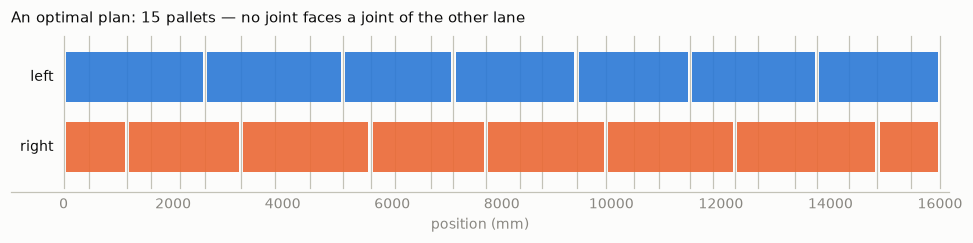

In [3]:
bridge = random_instance(length=16000, seed=1)
print(f"{bridge.length} mm, {len(bridge.planks)} planks, {len(bridge.candidates())} candidate pallets")

plan = run_solver(bridge, "graph")
assert verify(bridge, plan) == []
draw_plan(bridge, plan, title=f"An optimal plan: {plan.pallet_count} pallets — no joint faces a joint of the other lane")
plt.show()

**The structure.** Take the planks as nodes and the candidate pallets as arcs.
A lane is a path from the first to the last plank, and the staggering rule
says that the two paths share no interior node. So the problem is *two paths
without a common interior node and with the fewest arcs* — a minimum-cost
flow of two units.

- `graph` solves exactly that with two shortest-path computations.
- `graph-sequential` plans one lane after the other: the shortest left lane,
  then the shortest right lane that avoids its joints, and the next left lane
  if there is none.
- The MIP **flow** model (one variable per pallet) has an integral linear
  relaxation; the **exact cover** model is the direct set-cover formulation.
  Both are passed unchanged to SCIP and to CP-SAT.

## 2. The solvers, live

All six Python solvers on the bridge above. Every plan is checked with
`verify()`, which knows nothing about any solver.

In [4]:
rows = []
for solver in SOLVERS[:6]:
    started = time.perf_counter()
    result = run_solver(bridge, solver)
    elapsed = time.perf_counter() - started
    assert verify(bridge, result) == []
    rows.append({"solver": solver, "pallets": result.pallet_count, "status": result.status.value,
                 "time (ms)": round(elapsed * 1000, 1)})
pd.DataFrame(rows).set_index("solver")

,pallets,status,time (ms)
solver,,,
graph,15,optimal,2.8
graph-sequential,15,feasible,0.2
scip-flow,15,optimal,23.2
cpsat-flow,15,optimal,44.6
scip-cover,15,optimal,38.0
cpsat-cover,15,optimal,48.4


### Timefold

Timefold is a constraint solver based on local search: it builds a first plan
with a construction heuristic and then improves it move by move. It never
proves optimality. The two models differ only in what a planning entity is:

- **pallets** — one entity per candidate pallet; the variable says whether it
  is laid in lane 1, in lane 2 or not at all. This is the direct translation
  of "select subsets". A plan is a chain of pallets that touch exactly, so
  replacing two pallets by a longer one needs three variables to change
  together — every single move opens a hole or creates an overlap.
- **joints** — one entity per lane and plank; the variable says whether the
  lane has a joint there. Pallets run from joint to joint, so a lane is
  covered *by construction*, and removing one joint merges two pallets.

The next cell runs both for five seconds on the same bridge, if Java and the
runner are available.

In [5]:
JAR = ROOT / "timefold" / "target" / "fixed-planks-timefold.jar"


def java_version():
    java = shutil.which("java")
    if java is None:
        return None
    text = subprocess.run([java, "-version"], capture_output=True, text=True).stderr
    try:
        return int(text.split('"')[1].split(".")[0])
    except (IndexError, ValueError):
        return None


version = java_version()
if version is None or version < 21 or not JAR.exists():
    print("Skipped: this cell needs Java 21 or newer and the runner built with 'make timefold'.")
    print("The stored benchmark results below cover the Timefold models.")
else:
    with tempfile.TemporaryDirectory() as folder:
        path = Path(folder) / "bridge.json"
        bridge.save(path)
        rows = []
        for model in ("joints", "pallets"):
            command = ["java", "-jar", str(JAR), "--instance", str(path), "--model", model,
                       "--seconds", "5", "--target", str(plan.pallet_count)]
            text = subprocess.run(command, capture_output=True, text=True, check=True).stdout.strip().splitlines()[-1]
            result = BridgePlan.from_json(text)
            assert verify(bridge, result) == []
            rows.append({"model": f"timefold-{model}", "pallets": result.pallet_count,
                         "optimum": plan.pallet_count, "time (s)": round(json.loads(text)["solve_ms"] / 1000, 1)})
    display(pd.DataFrame(rows).set_index("model"))

,pallets,optimum,time (s)
model,,,
timefold-joints,15,15,1.1
timefold-pallets,29,15,5.2


## 3. The benchmark

`make benchmark` solves random bridges of 16 to 128 m, three per length, with
all eight solvers and writes `docs/benchmark/results.csv`. A Timefold run
stops when it reaches the optimum or after 30 seconds; its time is the
solver's own, without the start of the JVM.

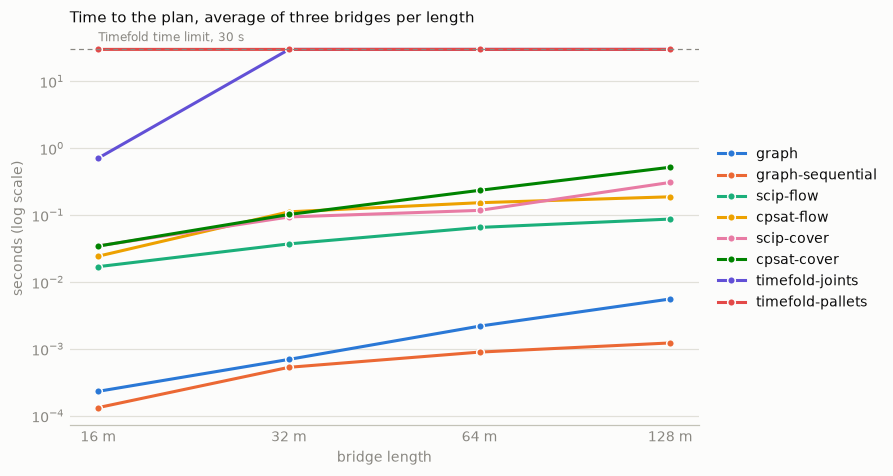

,planks,candidates
length,,
16000,30,98
32000,59,199
64000,115,400
128000,234,832


In [6]:
results = pd.read_csv(ROOT / "docs" / "benchmark" / "results.csv")
results["above"] = (results["pallets"] - results["optimum"]) / results["optimum"]
by_length = results.groupby(["length", "solver"]).agg(seconds=("seconds", "mean"), above=("above", "mean")).reset_index()
size = results[results.solver == "graph"].groupby("length").agg(planks=("planks", "mean"), candidates=("candidates", "mean"))

fig, ax = plt.subplots(figsize=(8.2, 4.4))
style(ax)
for solver in SOLVERS:
    data = by_length[by_length.solver == solver]
    ax.plot(data.length / 1000, data.seconds, color=COLOUR[solver], linewidth=2, marker="o", markersize=5,
            markeredgecolor="#fcfcfb", markeredgewidth=1, label=solver)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks([16, 32, 64, 128], ["16 m", "32 m", "64 m", "128 m"])
ax.minorticks_off()
ax.axhline(30, color=MUTED, linewidth=0.8, linestyle=(0, (4, 3)))
ax.text(16, 36, "Timefold time limit, 30 s", color=MUTED, fontsize=8, va="bottom")
ax.set_ylabel("seconds (log scale)", color=MUTED)
ax.set_xlabel("bridge length", color=MUTED)
ax.set_title("Time to the plan, average of three bridges per length", loc="left", color=INK, fontsize=10)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), labelcolor=INK)
fig.tight_layout()
plt.show()

size.round(0).astype(int)

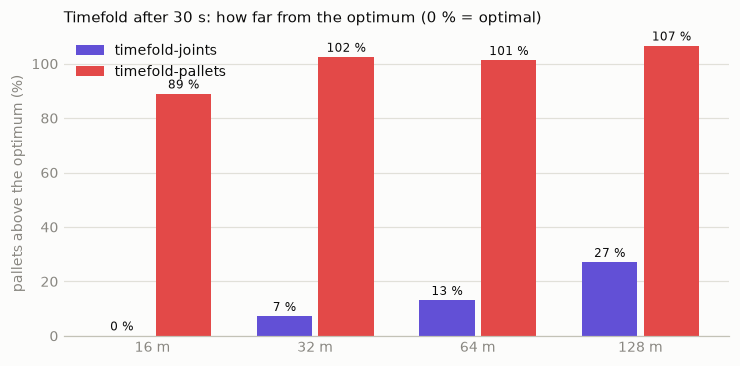

Largest distance from the optimum over all graph and MIP runs: 0%


In [7]:
timefold = by_length[by_length.solver.str.startswith("timefold")]
lengths = sorted(timefold.length.unique())

fig, ax = plt.subplots(figsize=(6.8, 3.4))
style(ax)
for offset, solver in ((-0.19, "timefold-joints"), (0.19, "timefold-pallets")):
    data = timefold[timefold.solver == solver].set_index("length").loc[lengths]
    bars = ax.bar([i + offset for i in range(len(lengths))], data.above * 100, width=0.34, color=COLOUR[solver], label=solver)
    for bar, value in zip(bars, data.above * 100):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 2, f"{value:.0f} %", ha="center", color=INK, fontsize=8)
ax.set_xticks(range(len(lengths)), [f"{length // 1000} m" for length in lengths])
ax.set_ylabel("pallets above the optimum (%)", color=MUTED)
ax.set_title("Timefold after 30 s: how far from the optimum (0 % = optimal)", loc="left", color=INK, fontsize=10)
ax.legend(frameon=False, loc="upper left", labelcolor=INK)
fig.tight_layout()
plt.show()

exact = by_length[~by_length.solver.str.startswith("timefold")]
print("Largest distance from the optimum over all graph and MIP runs:", f"{exact.above.max():.0%}")

**What the benchmark shows**

- The two graph algorithms and the four MIP variants return the optimum on
  every bridge, in milliseconds to a few tenths of a second. On this
  network-like structure SCIP is somewhat faster than CP-SAT.
- **The model decides how Timefold does.** With one entity per candidate
  pallet the construction heuristic finds a valid plan, and local search then
  cannot improve it — it stays at about twice the optimal number of pallets
  for the whole 30 seconds. With one entity per joint the same solver reaches
  the optimum on the 16 m bridge in under a second, and falls behind as the
  bridge grows.
- Neither Timefold model can say whether its plan is optimal.

The Timefold runs use the default configuration — one thread, no custom
moves. Custom moves would help the joints model further; they are exactly the
kind of problem knowledge the graph and MIP formulations use from the start.

## 4. A new requirement: cutting from stock pieces

A hypothetical extension, to see what each approach does when the problem
changes. Pallets are cut from **stock pieces of length M = 2 600 mm**, several
from one piece when their lengths add up to at most M, and the objective is
now the **fewest stock pieces** (then the fewest pallets).

- The graph view does not carry over: the cost of a pallet now depends on
  which other pallets share its stock piece. What is left is `graph-stock`:
  take the plan with the fewest pallets and cut it afterwards (first fit
  decreasing).
- The MIP takes the requirement as three more constraints on top of the flow
  model (**model C**), and the same model again goes to SCIP and to CP-SAT.

The two lanes are 2·L long in total, so ⌈2·L/M⌉ stock pieces is a lower bound.

,stock pieces,lower bound,pallets,status,time (s)
solver,,,,,
graph-stock,12,10,12,feasible,0.00
scip-stock,10,10,13,optimal,23.77
cpsat-stock,10,10,13,optimal,0.32


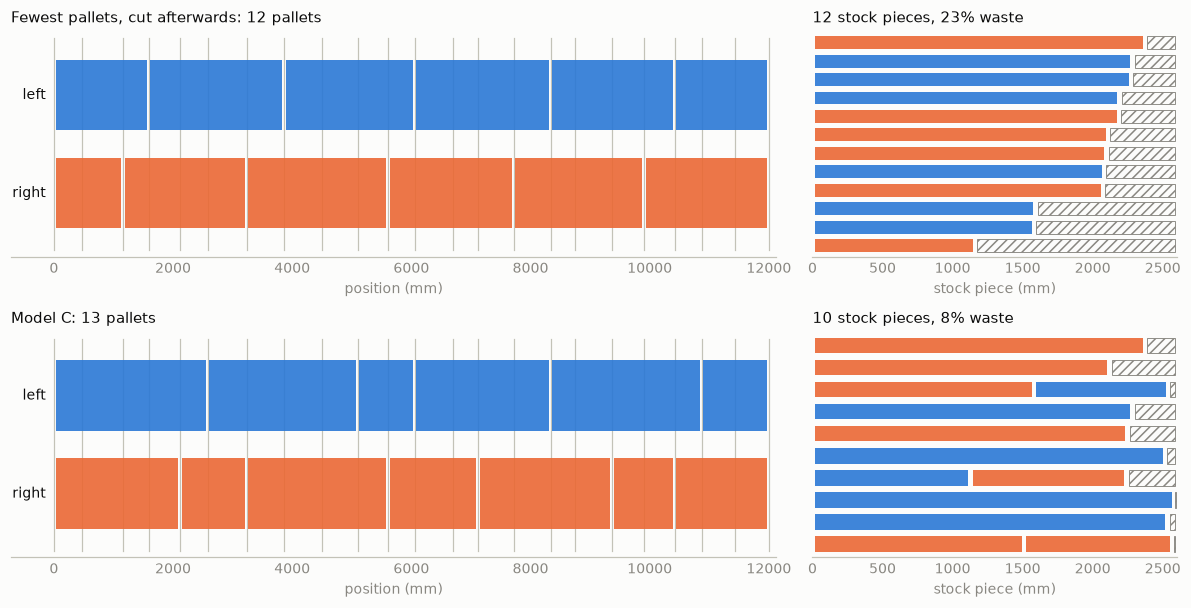

In [8]:
bridge12 = random_instance(length=12000, seed=1)
lower_bound = -(-2 * bridge12.length // bridge12.max_pallet)

plans, rows = {}, []
for solver in ("graph-stock", "scip-stock", "cpsat-stock"):
    started = time.perf_counter()
    result = run_solver(bridge12, solver, 60)
    elapsed = time.perf_counter() - started
    assert verify(bridge12, result) == [] and verify_cutting(bridge12, result) == []
    plans[solver] = result
    rows.append({"solver": solver, "stock pieces": len(result.stock), "lower bound": lower_bound,
                 "pallets": result.pallet_count, "status": result.status.value, "time (s)": round(elapsed, 2)})
display(pd.DataFrame(rows).set_index("solver"))

fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), gridspec_kw={"width_ratios": [2.1, 1], "height_ratios": [1, 1]})
for row, (solver, label) in enumerate((("graph-stock", "Fewest pallets, cut afterwards"), ("cpsat-stock", "Model C"))):
    result = plans[solver]
    draw_plan(bridge12, result, axes[row][0], title=f"{label}: {result.pallet_count} pallets")
    draw_cutting(bridge12, result, axes[row][1])
fig.tight_layout()
plt.show()

Blue pallets belong to the left lane, orange ones to the right lane; the
hatched part of a stock piece is waste. The plan with the fewest pallets uses
long pallets whose short remainders fit nothing else. Model C lays a few more,
shorter pallets whose lengths pair up on one stock piece.

The stored results for 8, 12 and 16 m bridges, five of each:

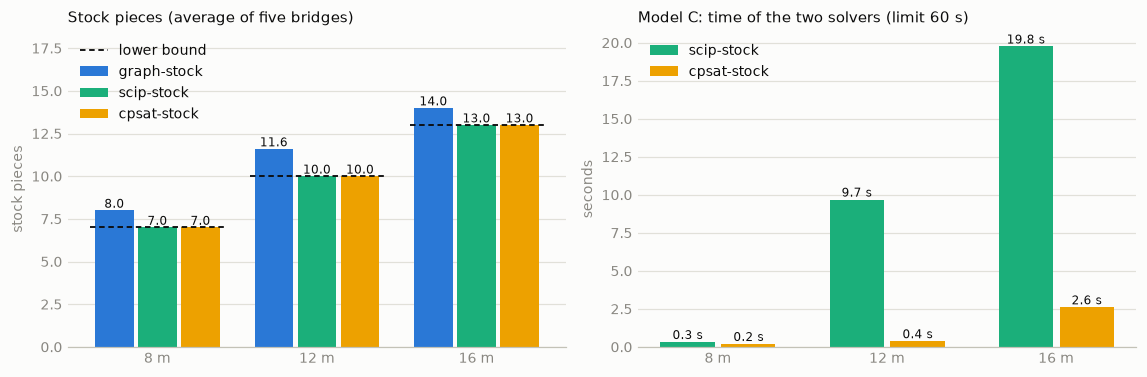

,SCIP proved optimal,CP-SAT proved optimal,runs
length,,,
8000,5,5,5
12000,5,5,5
16000,4,5,5


In [9]:
stock = pd.read_csv(ROOT / "docs" / "benchmark" / "stock.csv")
mean = stock.groupby("length").mean(numeric_only=True)
labels = [f"{length // 1000} m" for length in mean.index]
positions = range(len(mean))

fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.5))
style(left)
series = (("graph_pieces", "graph-stock", COLOUR["graph"]), ("scip_pieces", "scip-stock", COLOUR["scip-flow"]),
          ("cpsat_pieces", "cpsat-stock", COLOUR["cpsat-flow"]))
for index, (column, label, colour) in enumerate(series):
    bars = left.bar([p + (index - 1) * 0.27 for p in positions], mean[column], width=0.24, color=colour, label=label)
    for bar, value in zip(bars, mean[column]):
        left.text(bar.get_x() + bar.get_width() / 2, value + 0.15, f"{value:.1f}", ha="center", color=INK, fontsize=8)
for p, bound in zip(positions, mean.lower_bound):
    left.plot([p - 0.42, p + 0.42], [bound, bound], color=INK, linewidth=1.2, linestyle=(0, (3, 2)),
              label="lower bound" if p == 0 else None)
left.set_xticks(positions, labels)
left.set_ylim(0, mean.graph_pieces.max() * 1.32)
left.set_ylabel("stock pieces", color=MUTED)
left.set_title("Stock pieces (average of five bridges)", loc="left", color=INK, fontsize=10)
left.legend(frameon=False, loc="upper left", labelcolor=INK)

style(right)
for index, (column, label, colour) in enumerate((("scip_seconds", "scip-stock", COLOUR["scip-flow"]),
                                                 ("cpsat_seconds", "cpsat-stock", COLOUR["cpsat-flow"]))):
    bars = right.bar([p + (index - 0.5) * 0.36 for p in positions], mean[column], width=0.32, color=colour, label=label)
    for bar, value in zip(bars, mean[column]):
        right.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.1f} s", ha="center", va="bottom", color=INK, fontsize=8)
right.set_xticks(positions, labels)
right.set_ylabel("seconds", color=MUTED)
right.set_title("Model C: time of the two solvers (limit 60 s)", loc="left", color=INK, fontsize=10)
right.legend(frameon=False, loc="upper left", labelcolor=INK)
fig.tight_layout()
plt.show()

proved = stock.groupby("length").agg(scip=("scip_status", lambda s: (s == "optimal").sum()),
                                     cpsat=("cpsat_status", lambda s: (s == "optimal").sum()), runs=("seed", "count"))
proved.rename(columns={"scip": "SCIP proved optimal", "cpsat": "CP-SAT proved optimal"})

**What the extension shows**

- Model C reaches the lower bound on every one of these bridges; cutting the
  shortest plan afterwards needs about one stock piece more.
- The requirement cost three constraints. The flow part of the model, the
  checks and the tests stayed as they were.
- The roles of the two solvers swap. On the pure flow model SCIP was the
  faster one; on model C, whose cutting part has a weak linear relaxation and
  many symmetric solutions, CP-SAT is clearly faster and SCIP needs seconds to
  tens of seconds, with times that vary from run to run. One model, written
  once, was enough to try both.
- Model C in this simple form is for bridges of this size. Much longer ones
  would need a stronger formulation of the cutting.

## Summary

Looking at the structure of the problem first paid off three times: it gave a
graph algorithm that solves the basic problem instantly, a MIP whose
relaxation is already integral, and even a far better model for the local
search solver. A black-box solver did not remove the need to understand the
problem; and when the problem changed, the MIP was the formulation that took
the change.